# MMI 2x2 SiN 300 nm, 85:15

Reproduccion con upvfab_design_tools. La fuente original excita el puerto superior. Las dimensiones se expresan en micrometros.


17:22:46 Hora estándar romance WARNING: Using canonical configuration directory 
                               at 'C:\Users\camil\.config\tidy3d'. Found legacy 
                               directory at '~/.tidy3d', which will be ignored. 
                               Remove it manually or run 'tidy3d config migrate 
                               --delete-legacy' to clean up.                    


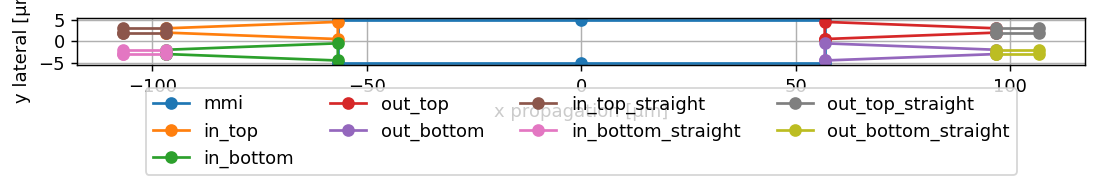

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tidy3d as td
from upvfab_design_tools.core import CrossSection, Rectangle, Material
from upvfab_design_tools.tidy3d_plugin import (
    mmi_2x2_vertices, build_mmi_2x2_fdtd_simulation,
    plot_fdtd_polygons, plot_fdtd_field_xy, load_tidy3d_simulation_data,
)
wl_um = 1.55
length_um, width_um = 113.5, 10.0
wg_um, thickness_um = 1.0, 0.3
taper_um, taper_length_um = 4.0, 40.0
gap_um = 1.0
port_y_um = (gap_um + taper_um)/2
si = Material('SiN original', 1.9729)
sio2 = Material('SiO2 original', np.sqrt(2.085136))
polygons = mmi_2x2_vertices(
    length_um=length_um, io_length_um=taper_length_um,
    io_y_position_um=port_y_um, access_width_um=wg_um,
    taper_width_um=taper_um, mmi_width_input_um=width_um,
    port_straight_length_um=10.0,
)
section = CrossSection(name='SiN300', background_material=sio2,
    x_min=-6, x_max=6, z_min=-1.7, z_max=1.7,
    structures=(Rectangle(x_min=-wg_um/2,x_max=wg_um/2,
        z_min=-thickness_um/2,z_max=thickness_um/2,material=si,name='core'),))
fig, ax = plot_fdtd_polygons(polygons)
ax.legend(loc='upper center', bbox_to_anchor=(0.5,-0.3), ncol=4)
plt.show()


## Simulacion FDTD

La construccion del paquete usa una fuente modal y monitores con configuracion distinta de la fuente original; por tanto, se compara como reproduccion numerica, no como simulacion identica.


In [2]:
sim = build_mmi_2x2_fdtd_simulation(
    polygons=polygons, cross_section=section, wavelength_um=wl_um,
    input_port='top', io_y_position_um=port_y_um, access_width_um=wg_um,
    monitor_wavelengths_um=np.linspace(1.50,1.60,51),
    pad_x_um=0, pad_y_um=2.3, pad_z_um=0,
    source_offset_um=1.775, monitor_offset_um=1.0,
    mode_plane_y_span_um=4.0, mode_plane_z_span_um=1.5,
    min_steps_per_wvl=15, run_time_s=5e-12,
)
print('Simulation size:', sim.size)
print('Monitors:', [m.name for m in sim.monitors])


Simulation size: (213.5, 14.6, 3.4)
Monitors: ['flux_reflection', 'mode_reflection', 'flux_top', 'flux_bottom', 'mode_top', 'mode_bottom', 'field_core']


## Carga o ejecucion

Usa el archivo de este dispositivo para reproducir las graficas. La estimacion y ejecucion cloud son explicitas.


In [3]:
DATA_PATH = Path('data/mmi2x2_sin300_8515_reproduction.hdf5')
LOAD_PREVIOUS_DATA = True
RUN_COST_ESTIMATE = False
RUN_CLOUD_SIMULATION = False
if LOAD_PREVIOUS_DATA and RUN_CLOUD_SIMULATION:
    raise ValueError('Choose saved data or a new simulation')
sim_data = None
if LOAD_PREVIOUS_DATA:
    sim_data = load_tidy3d_simulation_data(DATA_PATH)
if RUN_COST_ESTIMATE or RUN_CLOUD_SIMULATION:
    import tidy3d.web as web
    job = web.Job(simulation=sim, task_name='mmi2x2_sin300_8515_reproduction')
    if RUN_COST_ESTIMATE:
        print('Estimated FlexCredits:',job.estimate_cost())
    if RUN_CLOUD_SIMULATION:
        DATA_PATH.parent.mkdir(parents=True,exist_ok=True)
        sim_data = job.run(path=str(DATA_PATH))


## Campo y barrido espectral

Entrada superior: salida superior directa y salida inferior cruzada. El ancho de banda usa reparto 85:15 con tolerancia absoluta de 0.01.


At 1.5500 um: direct=0.146995, cross=0.853005, excess loss=0.4411 dB, cross-direct phase=89.85 deg
Continuous bandwidth around lambda0: 100.0 nm


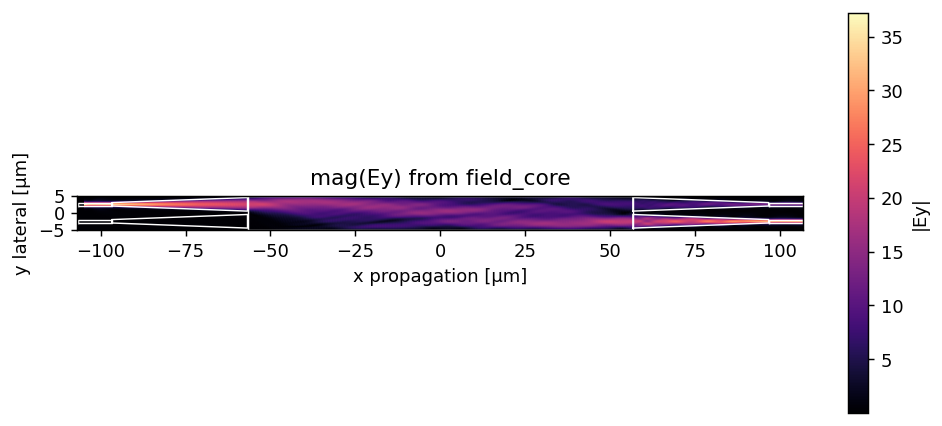

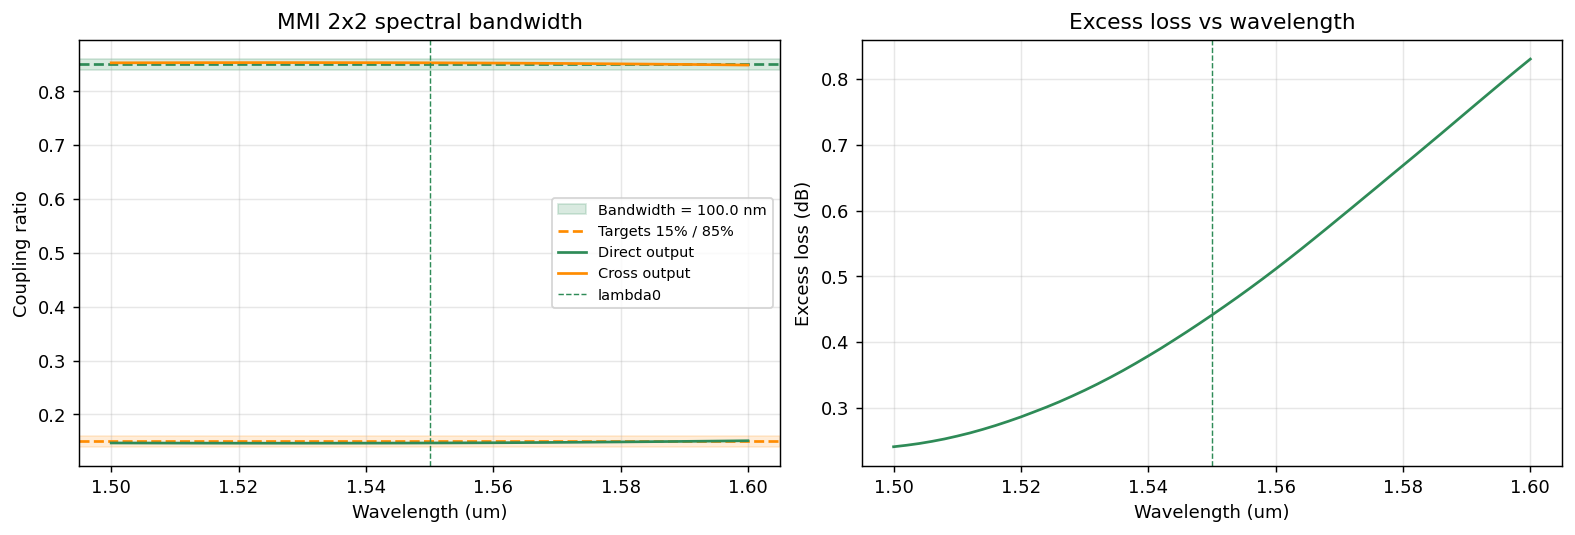

In [4]:
if sim_data is not None:
    fig, ax = plot_fdtd_field_xy(sim_data, monitor_name='field_core',
        field_component='Ey', field_part='mag', polygons=polygons, cmap='magma')
    plt.show()
    top = sim_data['mode_top'].amps.sel(direction='+',mode_index=0)
    bottom = sim_data['mode_bottom'].amps.sel(direction='+',mode_index=0)
    wl = td.C_0/np.asarray(top.f.values)
    pt, pb = np.abs(top.values)**2, np.abs(bottom.values)**2
    total = pt+pb
    split_t = np.divide(pt,total,out=np.full_like(total,np.nan,dtype=float),where=total>0)
    split_b = np.divide(pb,total,out=np.full_like(total,np.nan,dtype=float),where=total>0)
    loss = -10*np.log10(total)
    phase = np.rad2deg(np.angle(bottom.values*np.conj(top.values)))
    order=np.argsort(wl); wl,split_t,split_b,loss,phase=(a[order] for a in (wl,split_t,split_b,loss,phase))
    center=int(np.argmin(np.abs(wl-wl_um)))
    valid=(np.abs(split_t-.15)<=.01)&(np.abs(split_b-.85)<=.01)
    lo=hi=center
    if valid[center]:
        while lo>0 and valid[lo-1]: lo-=1
        while hi<len(wl)-1 and valid[hi+1]: hi+=1
    bandwidth=(wl[hi]-wl[lo])*1000 if valid[center] else 0
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    axes[0].axhspan(.14,.16,color='darkorange',alpha=.15)
    axes[0].axhspan(.84,.86,color='seagreen',alpha=.18,label=f'Bandwidth = {bandwidth:.1f} nm')
    axes[0].axhline(.15,color='darkorange',linestyle='--',label='Targets 15% / 85%')
    axes[0].axhline(.85,color='seagreen',linestyle='--')
    axes[0].plot(wl,split_t,color='seagreen',label='Direct output')
    axes[0].plot(wl,split_b,color='darkorange',label='Cross output')
    axes[0].axvline(wl_um,color='seagreen',linestyle='--',linewidth=.8,label='lambda0')
    axes[0].set(title='MMI 2x2 spectral bandwidth',xlabel='Wavelength (um)',ylabel='Coupling ratio')
    axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)
    axes[1].plot(wl,loss,color='seagreen'); axes[1].axvline(wl_um,color='seagreen',linestyle='--',linewidth=.8)
    axes[1].set(title='Excess loss vs wavelength',xlabel='Wavelength (um)',ylabel='Excess loss (dB)'); axes[1].grid(alpha=.3)
    plt.show()
    print(f'At {wl[center]:.4f} um: direct={split_t[center]:.6f}, cross={split_b[center]:.6f}, excess loss={loss[center]:.4f} dB, cross-direct phase={phase[center]:.2f} deg')
    print(f'Continuous bandwidth around lambda0: {bandwidth:.1f} nm')
